# Held-out validation of the calibrated model: resampling the surveys, the predictive band and where the in-sample protocol fails

**Question:** Does the throughput skill of the held-out CrusherCal protocol survive when the surveys are resampled, and is its 80 percent predictive band calibrated out of sample, as far as ten surveys can tell?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01, 02 and 03 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state what the held-out validation of the calibrated model claims over the paper's in-sample fit, and what evidence would support it and what would refute it;
- show the two conclusions that the in-sample protocol of the paper reaches and the held-out protocol reverses;
- test the throughput skill for robustness over every subset of seven surveys out of ten;
- measure the 80 percent predictive band twice, in sample and nested out of sample, and say which is which;
- state what this notebook cannot show of the claim.

## Setup

Numpy and matplotlib. The combinations of surveys and the binomial probabilities of the coverage use only the standard library.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the backbone builder and the CrusherCal module, with `itertools` for the subsets and `math` for the binomial coefficients.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import itertools
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv` and `VERSION`, the release label that the backbone document carries.

The cell reads the table and the release label.

In [2]:
# Read the survey table and the release label
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
print("surveys:", len(surveys), "| release label:", version)

surveys: 10 | release label: 0.13.000


## Method

**The comparison.** The product validates a calibrated crusher model out of sample on open industrial survey data, with a calibrated predictive band and pre-registered controls, delivered in the reader's browser. It differs from two published practices: the HP500 model of Rocha et al. (2024; https://doi.org/10.3390/min14090919), fitted and judged in sample on the same ten surveys, and the learned surrogates of comminution models (Koh et al., 2021; https://doi.org/10.1016/j.mineng.2021.107026), which report no held-out industrial parity and no uncertainty.

The claim can fail in four ways, and the notebook measures what a notebook can: the held-out numbers could show no skill over the baseline; the controls could beat the model; the skill could vanish when the surveys are resampled; or the band could be miscalibrated out of sample. The browser delivery is a property of the web application, covered by its own tests. The design document does not claim a comparison with a band of the paper, because this repository carries no source for one; the held-out error is set beside the in-sample error of the same backbone computed here. The cell runs CrusherCal's held-out protocol live on the ten surveys and prints the claim's ledger: the held-out error of the backbone, the in-sample error of the same backbone, the baseline, the residual model and the label-shuffle control, for the throughput.

Held-out validation is the discipline the discrete-element literature applies to its own crusher models, judged against experiments they were not tuned to (Johansson et al., 2017); a second industrial cone calibration, Duarte et al. (2021), reports no power, throw, speed or ore properties, so it cannot extend these ten surveys.

In [3]:
# CrusherCal's held-out protocol on the ten surveys, and the ledger of the claim for the throughput
doc = loo.build(backbone.build(surveys, version), version)
tph = doc["loo"]["tph"]["strict"]
print(f"backbone, held out          {tph['M0_backbone']['mape_pct']:6.2f} %")
print(f"same backbone, in sample    {doc['tph_parity']['backbone']['mape_pct']:6.2f} %")
print(f"constant-mean baseline      {tph['constant_mean']['mape_pct']:6.2f} %")
print(f"bounded-residual model      {tph['M1_residual']['mape_pct']:6.2f} %")
print(f"label-shuffle, seed 42      {tph['M1_label_shuffle']['mape_pct']:6.2f} %")

backbone, held out           12.09 %
same backbone, in sample     11.55 %
constant-mean baseline       18.29 %
bounded-residual model       13.45 %
label-shuffle, seed 42       25.04 %


The held-out error of the backbone, 12.09 percent, is close to the 11.55 percent of the same backbone judged in sample, so the hold-out costs little for the physics. It is far below the baseline of 18.29 percent, the bounded residual does not improve it, and the label-shuffle control at seed 42 is worse than the model; that is one draw, which notebook 02 repeats over 200 seeds. Those are the ledger lines of the claim that notebooks 02 and 03 compute step by step; this notebook adds what they cannot, the resampling and the calibration of the band.

## Comparison

The paper's protocol judges a calibrated model by its agreement with the data it was fitted to (notebook 03). The product's claim is that the held-out protocol reaches different conclusions where it matters. The cell states the two conclusions in question as comparisons, once in sample and once held out, from the live document: whether the free-form regression beats the calibrated backbone on the throughput, and whether the calibrated power form beats the constant mean on the power.

In [4]:
# The two conclusions of the in-sample protocol, tested again held out
for key, better, worse, text in (("tph", "M2_freeform", "M0_backbone", "free-form beats the backbone"),
                                 ("kW", "M0_backbone", "constant_mean", "backbone beats the mean")):
    for protocol, label in (("leaky", "in sample"), ("strict", "held out ")):
        a = doc["loo"][key][protocol][better]["mape_pct"]
        b = doc["loo"][key][protocol][worse]["mape_pct"]
        print(f"{key:4s} {text}: {label} {a < b!s:5s} ({a:5.2f} against {b:5.2f} %)")

tph  free-form beats the backbone: in sample True  ( 8.24 against 10.95 %)
tph  free-form beats the backbone: held out  False (12.18 against 12.09 %)
kW   backbone beats the mean: in sample True  (19.28 against 22.03 %)
kW   backbone beats the mean: held out  False (25.94 against 24.48 %)


Both conclusions flip. On the throughput the in-sample protocol says the free-form regression (8.24 percent) is far better than the backbone with its refitted scalar (10.95), and would recommend abandoning the physics for a regression; held out they tie, with the backbone ahead by a hair (12.18 and 12.09). On the power the in-sample refit of the paper's form (19.28 percent) beats the constant mean (22.03) and would credit the form with skill; held out the form (25.94) is worse than the mean (24.48). These are the two cases where the paper's in-sample protocol gets the answer wrong, and both come from the same cause: ten points leave room for a model with free coefficients to fit what is noise. Notebook 03 shows the full table behind them.

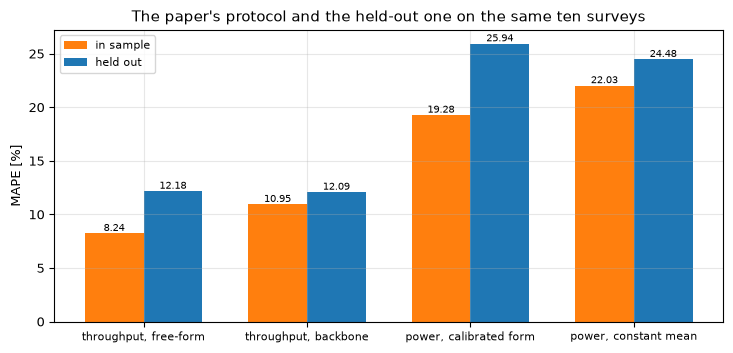

In [5]:
# Figure: in-sample against held-out MAPE of the four models behind the two flipped conclusions
pairs = (("tph", "M2_freeform", "throughput, free-form"), ("tph", "M0_backbone", "throughput, backbone"),
         ("kW", "M0_backbone", "power, calibrated form"), ("kW", "constant_mean", "power, constant mean"))
fig, ax = plt.subplots(figsize=(7.4, 3.6))
for k, (key, model, name) in enumerate(pairs):
    for shift, protocol, colour in ((-0.18, "leaky", "tab:orange"), (0.18, "strict", "tab:blue")):
        value = doc["loo"][key][protocol][model]["mape_pct"]
        ax.bar(k + shift, value, 0.36, color=colour,
               label=None if k else ("in sample" if protocol == "leaky" else "held out"))
        ax.annotate(f"{value:.2f}", (k + shift, value), ha="center", va="bottom", fontsize=7)
ax.set_xticks(range(len(pairs)), [p[2] for p in pairs], fontsize=8)
ax.set_ylabel("MAPE [%]")
ax.set_title("The paper's protocol and the held-out one on the same ten surveys")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The figure sets the published protocol, the orange bars, beside the product's, the blue ones, model by model. In sample, every fitted model gains: the free-form regression drops to 8.24 percent and the calibrated power form to 19.28, both below their comparators, which is what makes the in-sample protocol choose them. Held out, the orange advantage is gone: the free-form bar rises to 12.18 percent, level with the backbone's 12.09, and the power form rises to 25.94, above the constant mean's 24.48. The two models with a single number to fit move least, the backbone from 10.95 to 12.09 percent and the constant mean from 22.03 to 24.48, while the free-form regression and the power form, with more coefficients, move most. The bars do not show why the gap is larger for the free-form model than for the backbone; the count of coefficients does, three against one, as notebook 03 computes.

**Test 1, robustness of the skill to the choice of surveys.** One set of ten surveys is one sample. There are exactly $\binom{10}{7} = 120$ ways to choose seven of them, so the cell enumerates all of them with `itertools.combinations`, with no random draw and no repeat, rebuilds the backbone and the held-out validation on each, and counts the subsets where the held-out backbone beats the constant mean and where it beats the free-form regression, for the throughput and for the power. The 120 subsets are all there are, not a sample of them, and they overlap: each survey is in 84 of them, so the counts describe how the result depends on the choice of seven, and not 120 independent trials.

In [6]:
# Held-out validation on all 120 subsets of 7 surveys: the calibrated model minus the mean and minus the free-form one
subsets = list(itertools.combinations(range(10), 7))
margin = {(key, other): [] for key in ("tph", "kW") for other in ("constant_mean", "M2_freeform")}
for chosen in subsets:
    sub = loo.build(backbone.build([surveys[j] for j in chosen], version), version)["loo"]
    for key, other in margin:
        strict = sub[key]["strict"]
        margin[key, other].append(strict["M0_backbone"]["mape_pct"] - strict[other]["mape_pct"])
print("subsets enumerated:", len(subsets), "| distinct:", len(set(subsets)))
for key, label in (("tph", "throughput"), ("kW", "power")):
    beats_mean = int(np.sum(np.array(margin[key, "constant_mean"]) < 0))
    beats_free = int(np.sum(np.array(margin[key, "M2_freeform"]) < 0))
    print(f"{label:10s} backbone beats the mean in {beats_mean} of 120;", end=" ")
    print(f"beats the free-form regression in {beats_free} of 120")

subsets enumerated: 120 | distinct: 120
throughput backbone beats the mean in 120 of 120; beats the free-form regression in 80 of 120
power      backbone beats the mean in 36 of 120; beats the free-form regression in 10 of 120


The figure draws the margin of the backbone over the constant mean in each of the 120 subsets, the held-out MAPE of the backbone minus that of the mean: a negative value is a subset where the backbone wins.

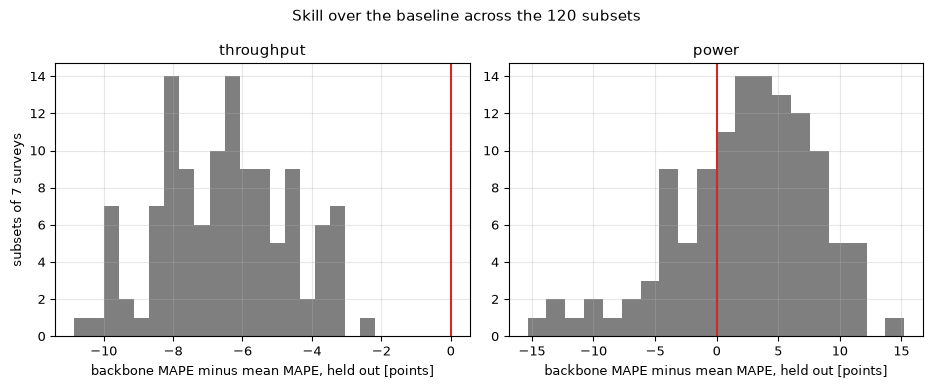

In [7]:
# Histogram of the margin of the backbone over the constant mean in the 120 subsets, for each target
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in zip(axes, ("tph", "kW"), ("throughput", "power")):
    ax.hist(margin[key, "constant_mean"], bins=20, color="tab:grey")
    ax.axvline(0, color="tab:red", lw=1.5)
    ax.set_xlabel("backbone MAPE minus mean MAPE, held out [points]")
    ax.set_title(label)
axes[0].set_ylabel("subsets of 7 surveys")
fig.suptitle("Skill over the baseline across the 120 subsets")
fig.tight_layout()
plt.show()

The throughput skill is robust: the backbone beats the constant mean in all 120 subsets, and the histogram of its margin lies entirely to the left of zero, so no choice of seven surveys makes it lose to the baseline. Against the free-form regression it wins in 80 of 120, exactly two thirds, a modest majority that agrees with the tie at ten surveys: the physics has no decisive edge over a regression on the setting, only the advantage of being a model. The power skill is not robust: the backbone beats the mean in only 36 of the 120 subsets, so in 84 it loses, and it beats the free-form regression in 10. The figure shows that the power histogram straddles zero with most of its mass on the losing side. The claim of the held-out validation is on the throughput and on the protocol, and the 120 subsets measure both; the overlap of the subsets means that this is a statement about the sensitivity to the choice of seven surveys, and a larger set of surveys would be needed to say more.

**Test 2, the predictive band, in sample and nested.** CrusherCal wraps the backbone's held-out prediction in an 80 percent band, $\hat y \pm 1.2816\,\sigma$, with $\sigma$ the sample standard deviation of the held-out residuals (`predictive_band`; the factor 1.2816 is the normal 80 percent two-sided quantile). The coverage of that band can be measured in two ways, and they answer different questions. The first, called in sample, computes $\sigma$ from the ten held-out residuals and then asks how many of those same ten residuals fall inside the band: $\sigma$ has seen the very residuals it is checked against. The second, called nested, is out of sample: for survey $i$, $\sigma_i$ comes from the held-out residuals of the other nine surveys only (`nested_band_coverage`), and survey $i$ is covered when its own residual lies within $1.2816\,\sigma_i$. Out of sample here has one qualification: each held-out residual that sizes $\sigma_i$ comes from a fold fitted on all surveys but its own, so survey $i$ is inside the fits behind the residuals that size its band, through what each fold refits (one scalar for the throughput, two coefficients for the power); the leak is second order and is not removed. The first cell builds the in-sample band for both targets from the live document's held-out predictions.

In symbols, with $r_i = y_i - \hat y_{-i}$ the held-out residual of survey $i$, $z_{q}$ the two-sided normal quantile of level $q$ ($z_{0.8} = 1.2816$) and $\mathbf{1}\{\cdot\}$ the indicator,

$$\hat\sigma = \sqrt{\frac{1}{n - 1} \sum_{i=1}^{n} (r_i - \bar r)^2}, \qquad \hat c_{\mathrm{in}} = \frac{1}{n} \sum_{i=1}^{n} \mathbf{1}\bigl\{ |r_i| \le z_q\, \hat\sigma \bigr\}, \qquad \hat c_{\mathrm{nested}} = \frac{1}{n} \sum_{i=1}^{n} \mathbf{1}\bigl\{ |r_i| \le z_q\, \hat\sigma_{-i} \bigr\},$$

where $\hat\sigma_{-i}$ is the same standard deviation computed without survey $i$. The only difference between the two coverages is whether the residual being judged helped to size its own band; the nested one is the honest estimate of how often an eleventh survey would fall inside.

In [8]:
# The in-sample 80 % band: sigma from the ten held-out residuals, and the share of those residuals inside it
resid = {key: np.array(doc["loo"][key]["measured"]) - np.array(doc["loo"][key]["strict"]["pred"]["M0"])
         for key in ("tph", "kW")}
print("band factor for 80 %:", loo.band_factor(0.8))
for key, label in (("tph", "throughput [t/h]"), ("kW", "power [kW]")):
    band = loo.predictive_band(resid[key])
    inside = np.abs(resid[key]) <= band["halfwidth"]
    print(f"{label:16s} sigma {band['sigma']:7.2f}  half-width {band['halfwidth']:7.2f}", end="  ")
    print(f"coverage {inside.mean():.2f}", end="  ")
    print("outside: survey", np.flatnonzero(~inside) + 1)
print("mean held-out residual: throughput", round(float(resid["tph"].mean()), 2), "t/h | power",
      round(float(resid["kW"].mean()), 2), "kW")

band factor for 80 %: 1.2816
throughput [t/h] sigma  186.09  half-width  238.50  coverage 0.90  outside: survey [1]
power [kW]       sigma   81.98  half-width  105.06  coverage 0.90  outside: survey [7]
mean held-out residual: throughput -6.6 t/h | power -10.81 kW


The second cell measures the nested coverage with `loo.nested_band_coverage`: the sigma that each survey would have been given by the other nine, and the verdict for each survey. The band of Test 2 is centred on the prediction, while its $\sigma$ is the spread of the residuals around their own mean $\bar r$, printed above: a model with a mean bias gets a band of the right width placed off centre by $\bar r$, a small shift here: the mean residual of the power is -10.81 kW, the prediction on average above the measurement.

In [9]:
# The nested out-of-sample coverage: sigma of each survey from the other nine residuals only
nested = {key: loo.nested_band_coverage(resid[key]) for key in ("tph", "kW")}
for key, label in (("tph", "throughput [t/h]"), ("kW", "power [kW]")):
    outside = np.flatnonzero(~np.array(nested[key]["covered"])) + 1
    print(f"{label:16s} sigma of the other nine, by survey:", np.round(nested[key]["sigma"], 1))
    print(f"{'':16s} nested coverage {nested[key]['coverage']:.2f}  outside: survey {outside}")

throughput [t/h] sigma of the other nine, by survey: [123.2 197.3 195.1 189.4 196.6 178.2 195.7 196.6 179.5 196.6]
                 nested coverage 0.80  outside: survey [1 6]
power [kW]       sigma of the other nine, by survey: [83.6 84.7 86.8 81.2 80.4 81.5 69.4 86.5 82.5 81.9]
                 nested coverage 0.90  outside: survey [7]


The figure draws, for the throughput, the held-out prediction of each survey with its two bands, the in-sample band of one fixed half-width and the nested band whose half-width changes with the sigma of the other nine, against the measurement.

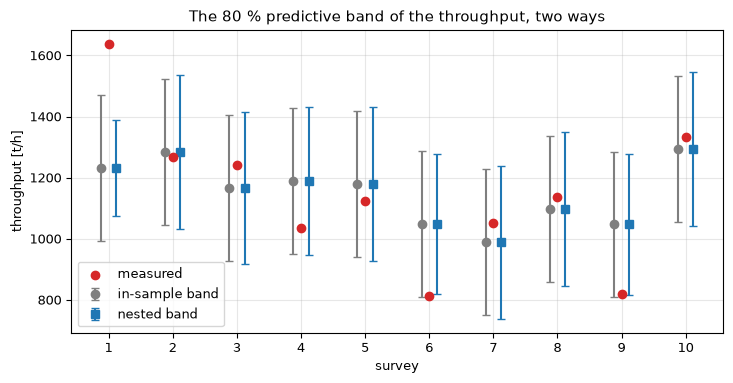

In [10]:
# The ten measurements against the held-out predictions with the in-sample band and the nested band, throughput
held = np.array(doc["loo"]["tph"]["strict"]["pred"]["M0"])
truth = np.array(doc["loo"]["tph"]["measured"])
fixed = loo.predictive_band(resid["tph"])["halfwidth"]
nested_half = loo.band_factor(0.8) * np.array(nested["tph"]["sigma"])
x = np.arange(1, 11)
fig, ax = plt.subplots()
ax.errorbar(x - 0.12, held, yerr=fixed, fmt="o", capsize=3, color="tab:grey", label="in-sample band")
ax.errorbar(x + 0.12, held, yerr=nested_half, fmt="s", capsize=3, color="tab:blue", label="nested band")
ax.scatter(x, truth, color="tab:red", zorder=3, label="measured")
ax.set_xticks(x)
ax.set_xlabel("survey")
ax.set_ylabel("throughput [t/h]")
ax.set_title("The 80 % predictive band of the throughput, two ways")
ax.legend()
fig.tight_layout()
plt.show()

The two coverages differ on the throughput, and the difference is the point. In sample, nine of the ten surveys fall inside the band (0.90, only survey 1 outside), because $\sigma$ = 186.09 t/h was computed with survey 1's own residual among the ten. Nested, only eight do (0.80, surveys 1 and 6 outside): the other nine residuals give survey 1 a $\sigma$ of just 123.2 t/h, because the survey that is hardest to predict is no longer in the sample that sizes its band, and its residual of 407 t/h falls far outside the narrower band. The in-sample 0.90 is the optimism this notebook exists to expose, and it is not the figure to read as calibration; the nested 0.80 is the out-of-sample coverage, and it equals the nominal level. The band is not small: its in-sample half-width of 238.50 t/h tells a user that the next survey will be anywhere in a range of 477 t/h, which is honest for a model that only knows the setting. For the power the two coverages agree at 0.90, with survey 7 outside in both (the other nine give it a $\sigma$ of 69.4 kW against 81.98 kW with it), and the half-width of 105.06 kW is wide for a quantity that notebook 02 of topic 05 measured between 187 and 355 kW, which is what no skill looks like.

With ten surveys the coverage can only take the values 0, 0.1, ... 1, so both numbers are coarse. If the band were exactly calibrated, the number of surveys inside it would follow a binomial law with $n = 10$ and $p = 0.8$. The cell computes the probability of each observed count under that law, and the probability of a count at least as extreme.

The law is

$$P(K = k) = \binom{n}{k}\, p^{k} (1 - p)^{n - k}, \qquad k = 0, 1, \dots, n,$$

with $K$ the number of surveys inside a band of true coverage $p$ and $n = 10$; at $p = 0.8$ its standard deviation is $\sqrt{n p (1 - p)} \approx 1.26$ surveys, more than one survey either way, which is the resolution of every coverage this notebook can report.

In [11]:
# Binomial reference for an exactly calibrated 80 % band: the probability of the observed counts
pmf = [math.comb(10, k) * 0.8 ** k * 0.2 ** (10 - k) for k in range(11)]
for key, label in (("tph", "throughput"), ("kW", "power")):
    half = loo.predictive_band(resid[key])["halfwidth"]
    inside = float(np.mean(np.abs(resid[key]) <= half))
    for kind, coverage in (("in sample", inside), ("nested", nested[key]["coverage"])):
        k = round(coverage * 10)
        print(f"{label:10s} {kind:9s} {k} of 10: P(count = {k}) = {pmf[k]:.4f},", end=" ")
        print(f"P(count >= {k}) = {sum(pmf[k:]):.4f}, P(count <= {k}) = {sum(pmf[:k + 1]):.4f}")

throughput in sample 9 of 10: P(count = 9) = 0.2684, P(count >= 9) = 0.3758, P(count <= 9) = 0.8926
throughput nested    8 of 10: P(count = 8) = 0.3020, P(count >= 8) = 0.6778, P(count <= 8) = 0.6242
power      in sample 9 of 10: P(count = 9) = 0.2684, P(count >= 9) = 0.3758, P(count <= 9) = 0.8926
power      nested    9 of 10: P(count = 9) = 0.2684, P(count >= 9) = 0.3758, P(count <= 9) = 0.8926


Under an exactly calibrated 80 percent band, 9 surveys of 10 inside has probability 0.2684 (0.3758 for 9 or more) and 8 of 10 has 0.3020 (0.6778 for 8 or more, 0.6242 for 8 or fewer). Every count the cells observed, 8 or 9, is an ordinary outcome of a calibrated band, so the data cannot distinguish this band from an exactly calibrated one. They cannot distinguish it from a band of somewhat different true coverage either, since with ten surveys the binomial is wide. The honest statement is that the out-of-sample coverage, 0.80 on the throughput and 0.90 on the power, is consistent with the nominal 0.80 and that ten surveys cannot establish it more precisely. This reading replaces the one that takes the in-sample 0.90 for a calibration, and it is the reason the product reports the two coverages separately.

### Sensitivity of the band to its level: a calibration curve on ten surveys

One level is one point of a calibration curve. The functions take the level as an argument, so the cell computes the nested coverage of both targets at six nominal levels from 0.5 to 0.95, with the factor `band_factor` gives for each, and draws it against the nominal level beside the diagonal of a perfect band and the 10 to 90 percent range of the count that a perfectly calibrated band would produce on ten surveys, from the binomial law above. A band that is miscalibrated in a way ten surveys can detect would leave that range.

level 0.50 (factor 0.6745): nested coverage tph 0.6, kW 0.2 | calibrated range 0.3 to 0.7
level 0.60 (factor 0.8416): nested coverage tph 0.7, kW 0.4 | calibrated range 0.4 to 0.8
level 0.70 (factor 1.0364): nested coverage tph 0.7, kW 0.8 | calibrated range 0.5 to 0.9
level 0.80 (factor 1.2816): nested coverage tph 0.8, kW 0.9 | calibrated range 0.6 to 1.0
level 0.90 (factor 1.6449): nested coverage tph 0.9, kW 0.9 | calibrated range 0.8 to 1.0
level 0.95 (factor 1.9600): nested coverage tph 0.9, kW 0.9 | calibrated range 0.9 to 1.0


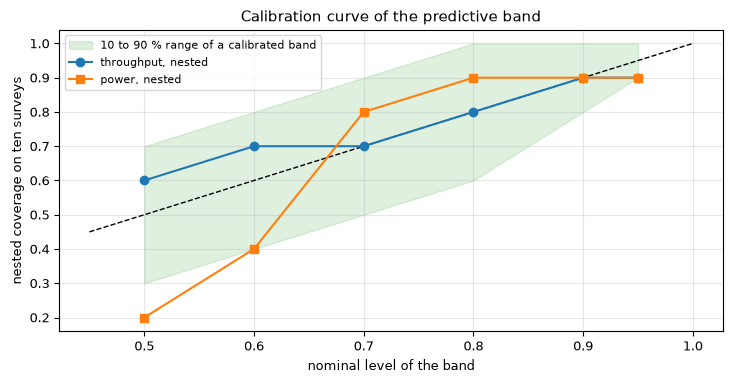

power, |residual| / sigma, sorted: [0.15 0.32 0.77 0.77 0.86 0.89 0.91 0.95 1.09 1.85]
z at the 0.5 and 0.7 levels: 0.6745 1.0364


In [12]:
# Nested coverage of both targets at six nominal levels, against the binomial range of a perfectly calibrated band
levels = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
curve = {key: [loo.nested_band_coverage(resid[key], lv)["coverage"] for lv in levels] for key in ("tph", "kW")}
def binomial_range(p, n=10):
    probs = [math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n + 1)]
    cdf = np.cumsum(probs)
    return int(np.searchsorted(cdf, 0.1)) / n, int(np.searchsorted(cdf, 0.9)) / n
ranges = [binomial_range(lv) for lv in levels]
for lv, f, (lo, hi), a, b in zip(levels, map(loo.band_factor, levels), ranges, curve["tph"], curve["kW"]):
    print(f"level {lv:.2f} (factor {f:.4f}): nested coverage tph {a:.1f}, kW {b:.1f}",
          f"| calibrated range {lo:.1f} to {hi:.1f}")
fig, ax = plt.subplots()
ax.fill_between(levels, [r[0] for r in ranges], [r[1] for r in ranges], color="tab:green", alpha=0.15,
                label="10 to 90 % range of a calibrated band")
ax.plot([0.45, 1.0], [0.45, 1.0], "k--", lw=1)
ax.plot(levels, curve["tph"], "o-", label="throughput, nested")
ax.plot(levels, curve["kW"], "s-", label="power, nested")
ax.set_xlabel("nominal level of the band")
ax.set_ylabel("nested coverage on ten surveys")
ax.set_title("Calibration curve of the predictive band")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
ratio = np.sort(np.abs(resid["kW"]) / loo.predictive_band(resid["kW"])["sigma"])
print("power, |residual| / sigma, sorted:", ratio.round(2))
print("z at the 0.5 and 0.7 levels:", round(loo.band_factor(0.5), 4), round(loo.band_factor(0.7), 4))

The throughput curve follows the diagonal closely at every level and stays inside the green range everywhere, so at this resolution its band is calibrated at all six levels, not only at the 80 percent the product ships. The power curve is the one that departs: at the 50 percent level only 0.2 of the surveys fall inside, below the 0.3 to 0.7 a calibrated band would give, and at 60 percent 0.4, on the lower edge of its range, so the central part of the power band is too narrow, while from 70 to 90 percent it covers at least its nominal level (0.8, 0.9 and 0.9), and at 95 percent it covers 0.9, the lower edge of the 0.9 to 1.0 range of a calibrated band. The sorted residuals printed above explain the shape. Measured in units of the power $\sigma$ of 81.98 kW, 7 of the 10 lie between 0.77 and 1.09, and the other three are two small ones (0.15 and 0.32) and one large one (1.85). Against the band factors the cell prints, only the two small ones fall inside the 0.6745 $\sigma$ of the 50 percent band; the two at 0.77 are inside the 0.8416 $\sigma$ of the 60 percent band; the four between 0.86 and 0.95 sit between that and the 1.0364 $\sigma$ of the 70 percent band; and the one at 1.09 lies just outside it. So the coverage jumps from 0.4 to 0.8 between the 60 and 70 percent levels: the residuals are concentrated at a similar size on both signs, a light-tailed, two-signed pattern, not a few large values among many small ones (which would inflate $\sigma$ and over-cover the centre). The nested $\sigma$ of the other nine stays between 69.4 and 86.8 kW, so the picture holds for the nested coverage too. It fits the power result of topic 05: a model that misses the setting by a similar amount on most surveys leaves residuals of that kind, not noise around a right model. The 80 percent band of the power happens to sit where its coverage looks right, which is a reason to read the whole curve and not one level.

### Using it on your own data: a prediction with its band for a new survey

A developer who wants the product's answer for a new operating point of this machine, with its uncertainty, needs three calls: the engine at the new setting and f80 for the capacity factor, the capacity base fitted on all ten surveys with `fit_capacity_base`, and the band from the ten held-out residuals with `predictive_band`, whose half-width does not depend on the new point. The cell does it for a setting of 46 mm and an f80 of 95 mm, inside the support of the calibration, and prints the prediction with its 80 percent band and the nested sigma range that says how much that band would change with one survey fewer. The same three calls run on a reader's own table of surveys, once `read_surveys` reads it and the backbone is rebuilt from it.

In [13]:
# A new operating point of this machine: the capacity model fitted on all ten surveys and its 80 % band
point = operating_from_survey(46.0, 95.0)
new_run = evaluate(point)
factors = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)).throughput_tph / HP500_QREF for s in surveys]
every_row = loo.fold_indices(10, 0, leaky=True)
q_base = loo.fit_capacity_base(np.array(factors), np.array([s.feed_tph for s in surveys]), every_row)
prediction = q_base * new_run.throughput_tph / HP500_QREF
band = loo.predictive_band(resid["tph"], 0.8)
print(f"capacity base on all ten: {q_base:.1f} t/h | envelope codes of the new point: {list(new_run.envelope_codes)}")
low, high = prediction - band["halfwidth"], prediction + band["halfwidth"]
print(f"prediction {prediction:.0f} t/h, 80 % band {low:.0f} to {high:.0f} t/h")
sigmas = nested["tph"]["sigma"]
print("nested sigma over the ten surveys [t/h]:", round(min(sigmas), 1), "to", round(max(sigmas), 1))

capacity base on all ten: 686.0 t/h | envelope codes of the new point: []
prediction 1137 t/h, 80 % band 899 to 1376 t/h
nested sigma over the ten surveys [t/h]: 123.2 to 197.3


The new point carries no envelope code, so it is a calibrated answer, and the band around it is wide: plus or minus about 240 t/h on a prediction near 1140 t/h, the honest width of a model that misses survey 1 by 407 t/h. The nested sigma ranges from about 123 to 197 t/h, so the band would be a third narrower if the hardest survey had never been measured, which is the dependence on single surveys that ten points carry. What a developer should check before showing such a band: that the point is inside the support (no code), that the band comes from held-out residuals and never from in-sample ones, and that the target is the throughput; a power band built the same way would be the band of a model with no skill, and the product does not offer one.

## Results

**Answer:** yes on the throughput, within the limits of ten surveys, and no on the power. The held-out protocol reverses two conclusions of the in-sample protocol: it removes the apparent advantage of a free-form regression over the throughput backbone (8.24 against 10.95 percent in sample, 12.18 against 12.09 held out) and it removes the apparent skill of the power form (19.28 against 22.03 percent in sample, 25.94 against 24.48 held out). The throughput skill survives the resampling: the backbone beats the constant mean held out in 120 of the 120 subsets of seven surveys, all of them enumerated without repeats, and the free-form regression in 80 of 120, while on the power it beats the mean in only 36 and the regression in 10. The 80 percent band is reported twice and the two must not be confused: its in-sample coverage is 0.90 on both targets, with sigma taken from the same ten residuals it is checked against; its nested out-of-sample coverage, with the sigma of each survey taken from the other nine, is 0.80 on the throughput and 0.90 on the power. 8 or more surveys of 10 inside the band have probability 0.6778 under an exactly calibrated band, so the out-of-sample coverage is consistent with the nominal level and ten surveys cannot say more.

For the held-out validation of the product this is the evidence: held-out validation with controls and a band, measured here, with the held-out error of the backbone, 12.09 percent, close to the 11.55 percent of the same backbone in sample and far below the 18.29 percent of the baseline, the bounded residual's failure to beat the backbone (13.45 percent) reported as the pre-registered null it is, and the label-shuffle control at seed 42, 25.04 percent, a single draw that notebook 02 repeats over 200 seeds. What the notebook does not show is the browser delivery of the claim, covered by the application's own tests; a comparison with a band of the paper, which this repository has no source for; or the generalisation to another crusher or ore, which ten surveys of one machine cannot give. And the power remains an honest negative, which the product does not claim.

## Summary

The held-out validation is a claim about method, not about a lower error: held-out validation, controls run enough times and a predictive band change what can be concluded from ten surveys. Measured here, the hold-out removes two false conclusions of the in-sample protocol, the throughput skill survives every one of the 120 resamplings of seven surveys, and the band's out-of-sample coverage, the nested one, is consistent with its nominal level, while the in-sample coverage must not be read as calibration and the power stays unpredicted. The next topic turns to the learned models and the same discipline applied to them.

Across levels the throughput band stays calibrated and the power band is too narrow in its centre, and a new survey of this machine gets its prediction and band from three public calls.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026

- Johansson et al. (2017), Cone crusher performance evaluation using DEM simulations and laboratory experiments for model validation, Minerals Engineering. https://doi.org/10.1016/j.mineng.2016.09.015
- Duarte, Yamashita, da Silva, Cota and Euzébio (2021), Calibration and Validation of a Cone Crusher Model with Industrial Data, Minerals 11(11), 1256. https://doi.org/10.3390/min11111256